# ftoc2.ipynb — original example executed

**Name:** Rinkle Sharma  
**Student ID:** 67784

Original code cells retained unchanged. The notebook uses Adam(lr=0.02), MAE and 100 epochs; the SGD comparison is in Neural_Networks_Completed.ipynb.

In [1]:
%matplotlib inline

In [2]:
import torch
from torch import nn # nn contains all of PyTorch's building blocks for neural networks
import matplotlib.pyplot as plt
import numpy as np

# Check PyTorch version
torch.__version__

'2.14.1+cpu'

In [3]:
def celcius_to_fahrenheit(c):
    return c * 9/5 + 32

def fahrenheit_to_celcius(f):
    return (f - 32) * 5/9

# Create a tensor with celcius values
c_values = torch.tensor(range(0, 100), dtype=torch.float32).unsqueeze(dim=1)
# Convert the celcius values to fahrenheit
f_values = celcius_to_fahrenheit(c_values)

#split into training and test data
train_split = int(0.8 * len(f_values)) # 80% of data used for training set, 20% for testing 
X_train, y_train = c_values[:train_split], f_values[:train_split]
X_test, y_test = c_values[train_split:], f_values[train_split:]
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
print(X_train[0], y_train[0])

torch.Size([80, 1]) torch.Size([80, 1]) torch.Size([20, 1]) torch.Size([20, 1])
tensor([0.]) tensor([32.])


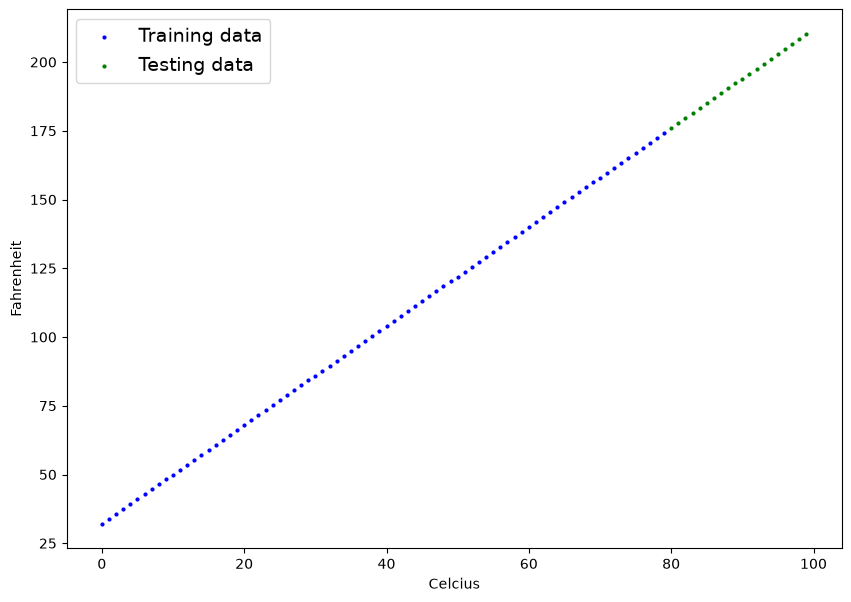

In [4]:
def plot_predictions(train_data=X_train, 
                     train_labels=y_train, 
                     test_data=X_test, 
                     test_labels=y_test, 
                     predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10, 7))
  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")
  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")
  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  plt.xlabel("Celcius")
  plt.ylabel("Fahrenheit")
  # Show the legend
  plt.legend(prop={"size": 14});

plot_predictions()

In [5]:
class LinearV1(nn.Module):
    def __init__(self):
        super().__init__() # <- initialize the parent class (nn.Module)
        self.weights = nn.Parameter(torch.randn(1, # <- start with random weights (this will get adjusted as the model learns)
                                                dtype=torch.float), # <- PyTorch loves float32 by default
                                   requires_grad=True) # <- can we update this value with gradient descent?)

        self.bias = nn.Parameter(torch.randn(1, # <- start with random bias (this will get adjusted as the model learns)
                                            dtype=torch.float), # <- PyTorch loves float32 by default
                                requires_grad=True) # <- can we update this value with gradient descent?))

    # Forward defines the computation in the model
    def forward(self, x: torch.Tensor) -> torch.Tensor: # <- "x" is the input data (e.g. training/testing features)
        return self.weights * x + self.bias # <- this is the linear regression formula (y = w*x + b)

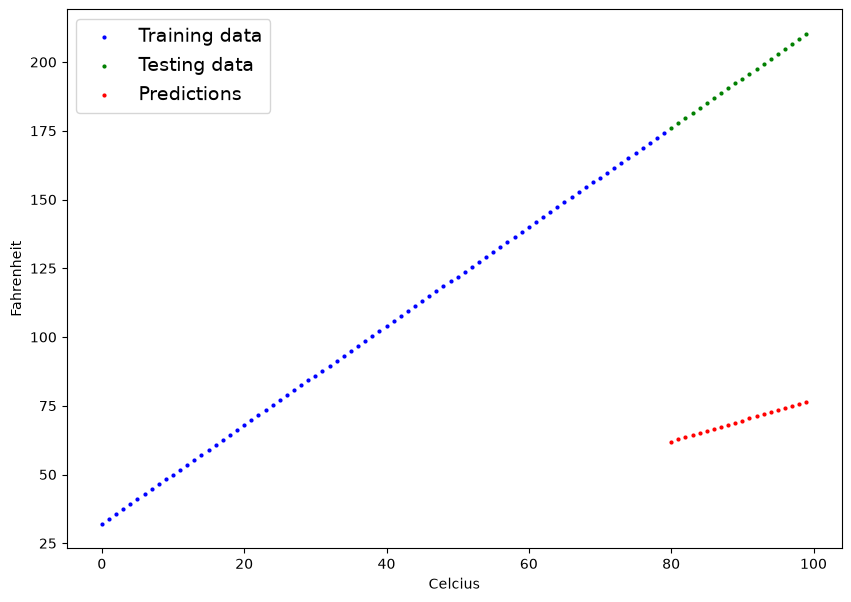

In [6]:
# Subclass nn.Module to make our model
class LinearV2(nn.Module):
    def __init__(self):
        super().__init__()
        # Use nn.Linear() for creating the model parameters
        self.linear_layer = nn.Linear(in_features=1, 
                                      out_features=1)
    
    # Define the forward computation (input data x flows through nn.Linear())
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)

# Set the manual seed when creating the model (this isn't always needed but is used for demonstrative purposes, try commenting it out and seeing what happens)
torch.manual_seed(42)
model_1 = LinearV2()
model_1, model_1.state_dict()
# Make predictions with model
with torch.inference_mode(): 
    y_preds = model_1(X_test)

plot_predictions(predictions=y_preds)

In [7]:
# Create the loss function
loss_fn = nn.L1Loss() #MSELoss() # nn.L1Loss() # MAE loss is same as L1Loss

# Create the optimizer
# optimizer = torch.optim.SGD(params=model_1.parameters(), # parameters of target model to optimize
#                             lr=0.01) # learning rate (how much the optimizer should change parameters at each step, higher=more (less stable), lower=less (might take a long time))
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.02)
                            

Epoch: 0 | MAE Train Loss: 72.07071685791016 | MAE Test Loss: 122.03379821777344 
Epoch: 10 | MAE Train Loss: 63.970726013183594 | MAE Test Loss: 103.9338150024414 
Epoch: 20 | MAE Train Loss: 55.8707275390625 | MAE Test Loss: 85.83382415771484 
Epoch: 30 | MAE Train Loss: 47.77074432373047 | MAE Test Loss: 67.73384857177734 
Epoch: 40 | MAE Train Loss: 39.670753479003906 | MAE Test Loss: 49.63385772705078 


Epoch: 50 | MAE Train Loss: 31.570758819580078 | MAE Test Loss: 31.53388023376465 
Epoch: 60 | MAE Train Loss: 23.470767974853516 | MAE Test Loss: 13.4339017868042 
Epoch: 70 | MAE Train Loss: 15.370773315429688 | MAE Test Loss: 4.666077613830566 
Epoch: 80 | MAE Train Loss: 12.367151260375977 | MAE Test Loss: 19.04831886291504 
Epoch: 90 | MAE Train Loss: 12.640947341918945 | MAE Test Loss: 23.873050689697266 


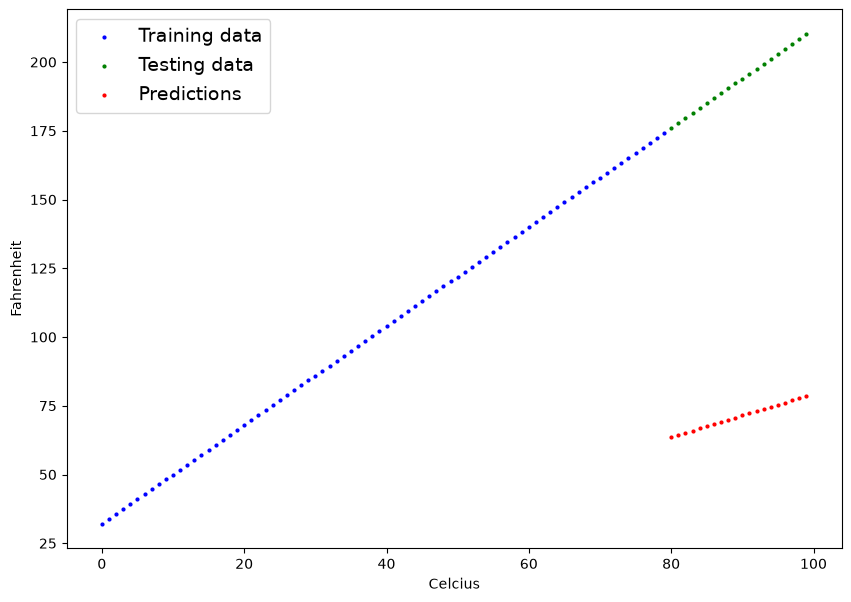

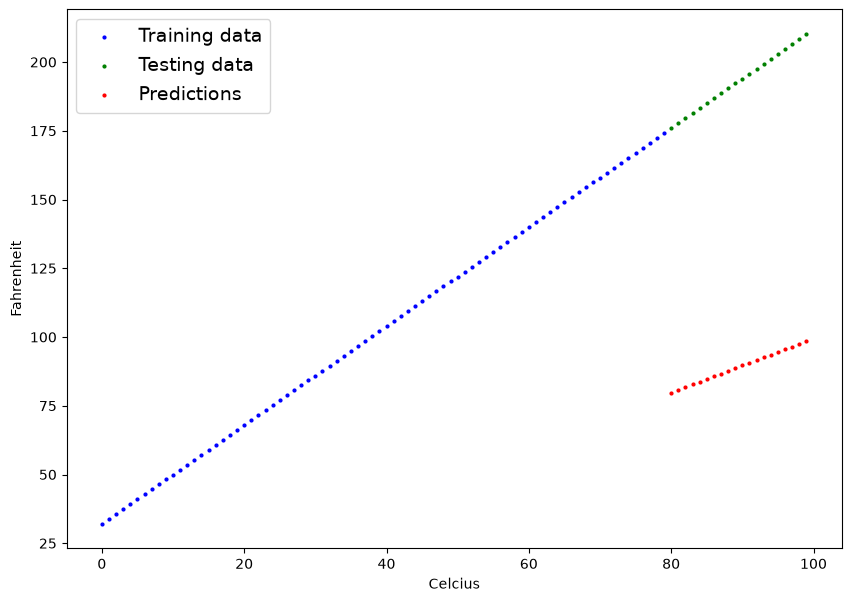

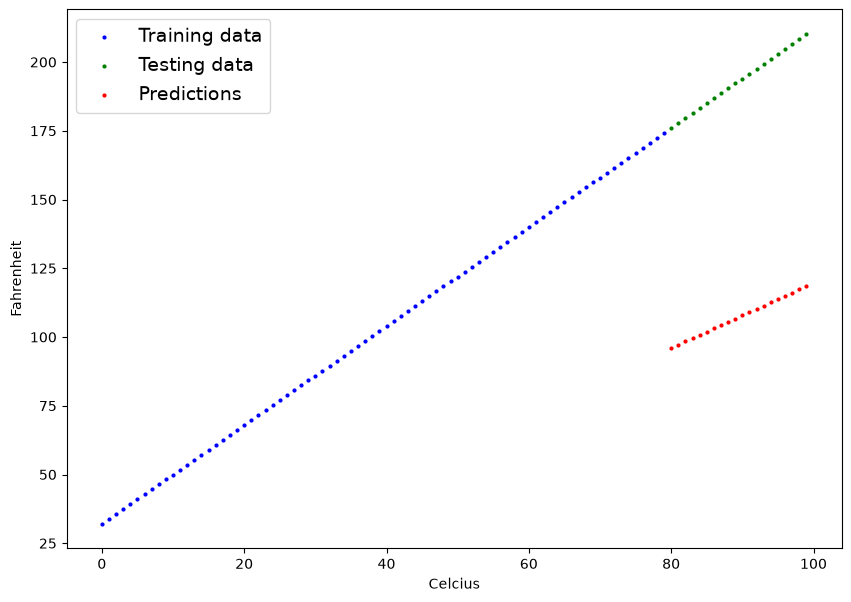

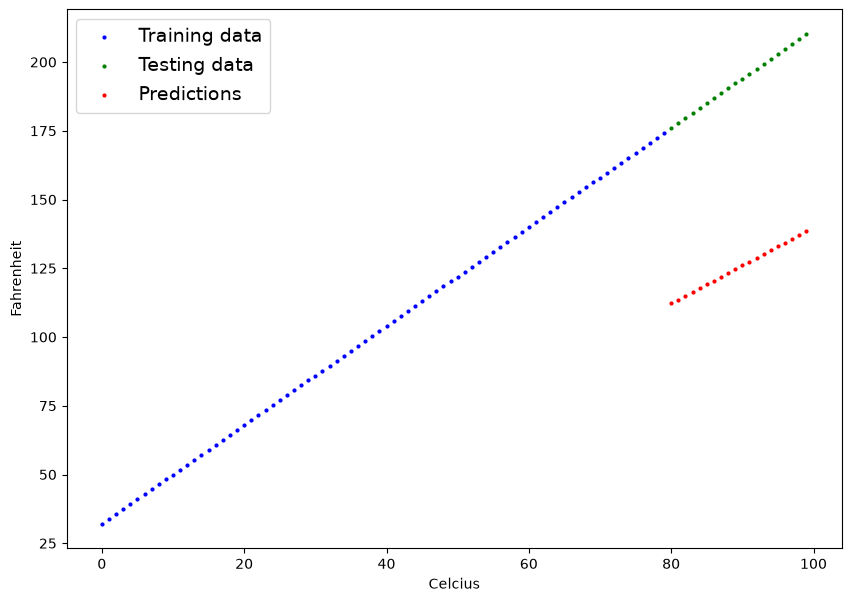

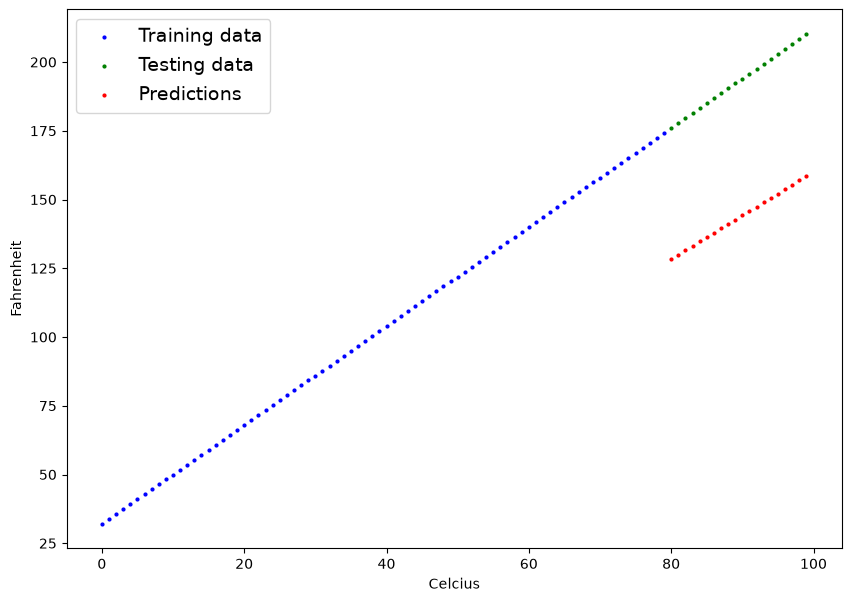

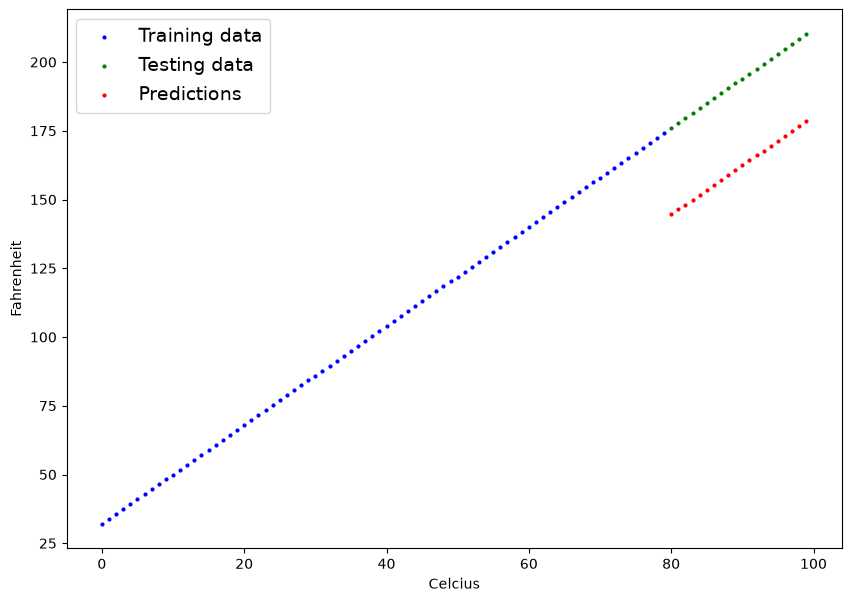

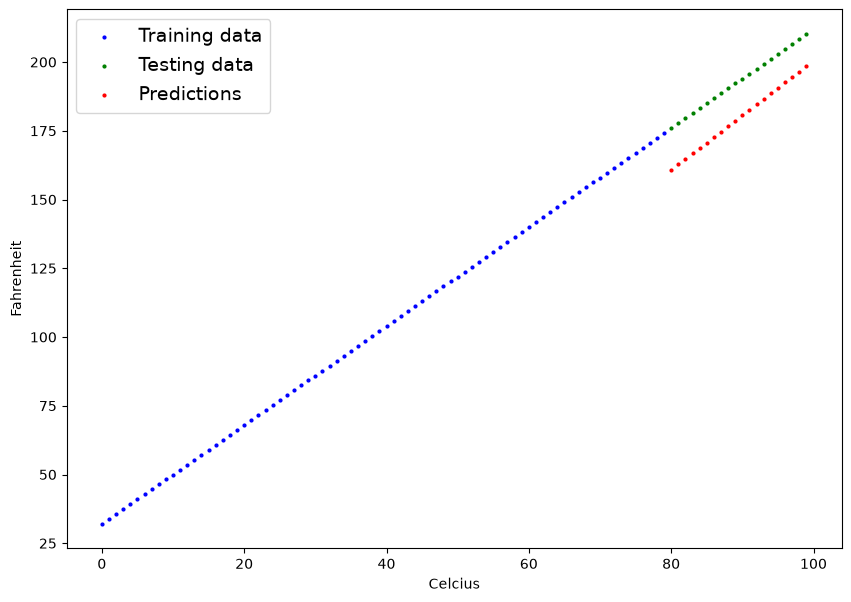

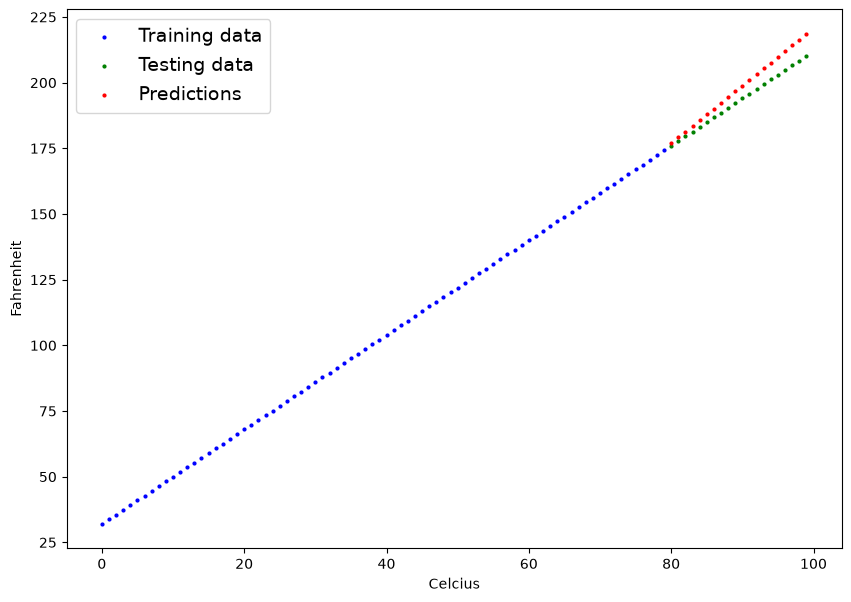

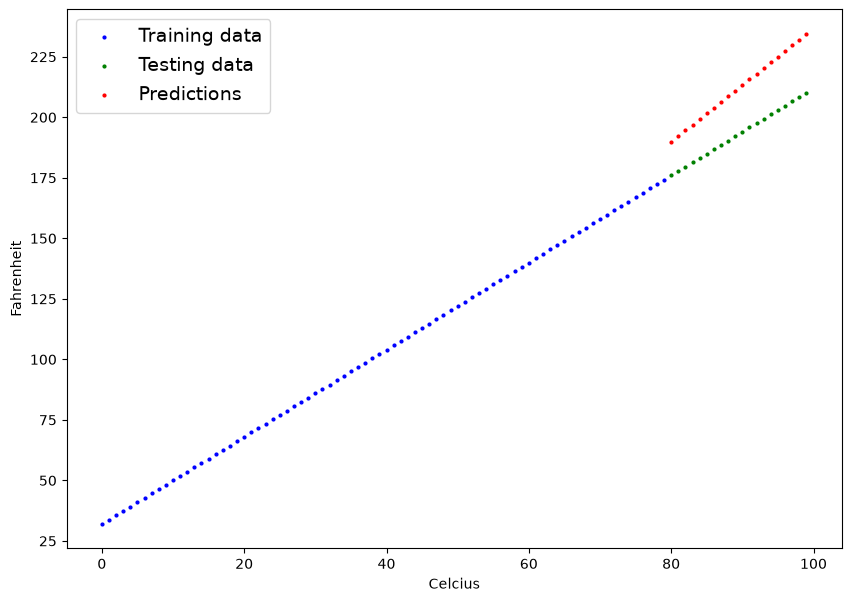

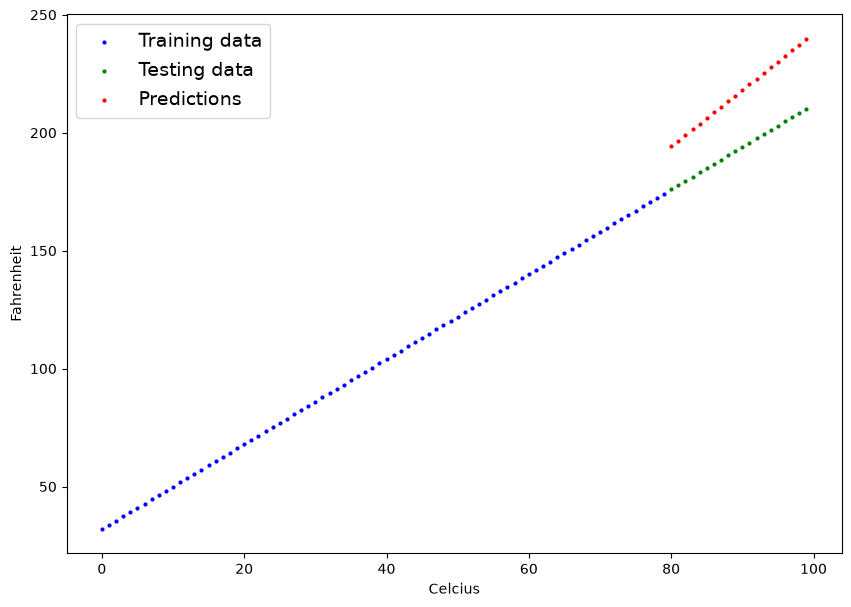

In [8]:
# Set the number of epochs (how many times the model will pass over the training data)
epochs = 100

# Create empty loss lists to track values
train_loss_values = []
test_loss_values = []
epoch_count = []

for epoch in range(epochs):
  ### Training

  # Put model in training mode (this is the default state of a model)
  model_1.train()

  # 1. Forward pass on train data using the forward() method inside 
  y_pred = model_1(X_train)
  # print(y_pred)

  # 2. Calculate the loss (how different are our models predictions to the ground truth)
  loss = loss_fn(y_pred, y_train)

  # 3. Zero grad of the optimizer
  optimizer.zero_grad()

  # 4. Loss backwards
  loss.backward()

  # 5. Progress the optimizer
  optimizer.step()

  ### Testing

  # Put the model in evaluation mode
  model_1.eval()

  with torch.inference_mode():
    # 1. Forward pass on test data
    test_pred = model_1(X_test)

    # 2. Caculate loss on test data
    test_loss = loss_fn(test_pred, y_test.type(torch.float)) # predictions come in torch.float datatype, so comparisons need to be done with tensors of the same type

    # Print out what's happening
  if epoch % 10 == 0:
        epoch_count.append(epoch)
        train_loss_values.append(loss.detach().numpy())
        test_loss_values.append(test_loss.detach().numpy())
        print(f"Epoch: {epoch} | MAE Train Loss: {loss} | MAE Test Loss: {test_loss} ")
        plot_predictions(predictions=test_pred)

In [9]:
print('Final original model:', model_1.state_dict())
with torch.inference_mode():
    print('Final test MAE:', loss_fn(model_1(X_test), y_test).item())

Final original model: OrderedDict({'linear_layer.weight': tensor([[2.3858]]), 'linear_layer.bias': tensor([2.6208])})
Final test MAE: 23.052227020263672
